# 🎙️ FASE 2 CRISP-DM: Data Understanding & Eksplorasi Sinyal Audio
## Sistem Deteksi Tingkat Keramaian Ruangan Berbasis Audio (*Crowd Level Detection*)

---

### 📋 Deskripsi Fase Data Understanding
Fase kedua dalam metodologi **CRISP-DM (*Cross-Industry Standard Process for Data Mining*)** bertujuan untuk:
1. Memahami karakteristik fisis dan statistik dari data sinyal audio digital.
2. Memverifikasi kualitas data (identifikasi missing values, data kosong, atau keheningan digital).
3. Melakukan eksplorasi sinyal audio baik pada **Domain Waktu (*Waveform*)** maupun **Domain Frekuensi (*Mel-Spectrogram*)**.
4. Menganalisis daya pembeda (*discriminative power*) dari 32 parameter fitur akustik yang diekstraksi menggunakan `librosa`.
5. Menemukan wawasan (*insights*) penting yang menjadi landasan bagi Fase Modeling (Random Forest).


---
## 1. Setup Lingkungan & Import Pustaka
Pustaka yang digunakan mencakup `librosa` untuk pemrosesan sinyal digital (DSP), `soundfile` untuk I/O audio, `pandas` & `numpy` untuk manipulasi data tabular, serta `matplotlib` & `seaborn` untuk visualisasi beresolusi tinggi.


In [1]:
import os
import glob
import soundfile as sf
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "figure.dpi": 120
})

DATASET_CSV = "../data/03_processed/audio_features_32.csv"
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv(DATASET_CSV)
print(f"Dataset berhasil dimuat: {df.shape[0]} sampel baris, {df.shape[1]} kolom.")


Dataset berhasil dimuat: 1285 sampel baris, 36 kolom.


---
## 2. Pemeriksaan Distribusi Sampel & Kualitas Data
Sebelum masuk ke analisis fitur, kita memeriksa rasio perbandingan kelas antara **Ramai (Kelas 1)** dan **Tidak Ramai (Kelas 0)**, baik pada tingkat file mentah asli (*parent files*) maupun pada tingkat segmen potongan (*audio chunks* @5 detik).


=== RINGKASAN DISTRIBUSI KELAS ===


,Parent Files (Asli),Audio Chunks (5 Detik),Persentase Chunks (%)
class_name,,,
ramai,97,742,57.74
tidak_ramai,89,543,42.26


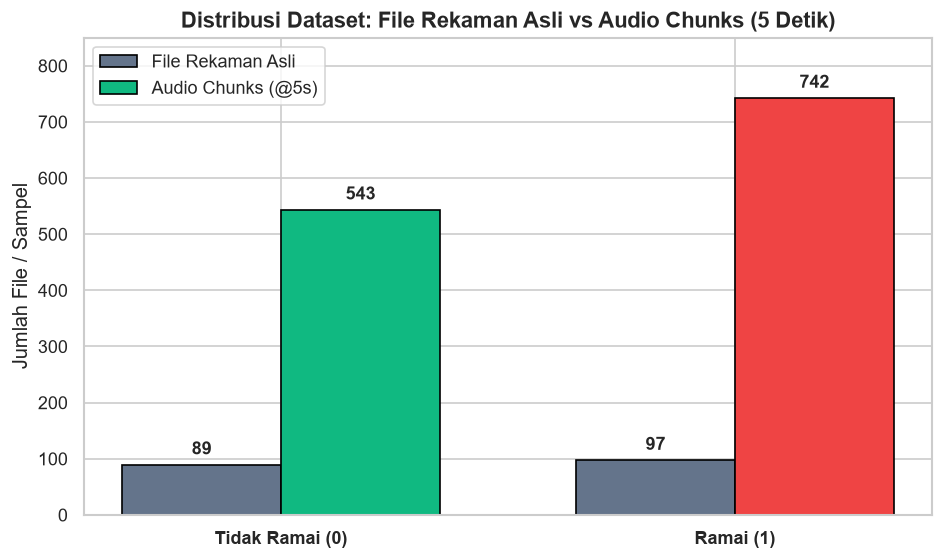

In [2]:
# Hitung distribusi
class_counts = df["class_name"].value_counts()
parent_counts = df.groupby("class_name")["parent_file"].nunique()

summary_dist = pd.DataFrame({
    "Parent Files (Asli)": parent_counts,
    "Audio Chunks (5 Detik)": class_counts,
    "Persentase Chunks (%)": (class_counts / len(df) * 100).round(2)
})
print("=== RINGKASAN DISTRIBUSI KELAS ===")
display(summary_dist)

# Visualisasi Bar Chart
fig, ax = plt.subplots(figsize=(8, 4.8))
categories = ["Tidak Ramai (0)", "Ramai (1)"]
raw_vals = [parent_counts["tidak_ramai"], parent_counts["ramai"]]
chunk_vals = [class_counts["tidak_ramai"], class_counts["ramai"]]

x = np.arange(len(categories))
width = 0.35

r1 = ax.bar(x - width/2, raw_vals, width, label="File Rekaman Asli", color="#64748b", edgecolor="black")
r2 = ax.bar(x + width/2, chunk_vals, width, label="Audio Chunks (@5s)", color=["#10b981", "#ef4444"], edgecolor="black")

ax.set_ylabel("Jumlah File / Sampel")
ax.set_title("Distribusi Dataset: File Rekaman Asli vs Audio Chunks (5 Detik)")
ax.set_xticks(x)
ax.set_xticklabels(categories, fontweight="bold")
ax.legend(frameon=True, facecolor="white")
ax.set_ylim(0, 850)

for rect in r1 + r2:
    h = rect.get_height()
    ax.annotate(f"{h}", xy=(rect.get_x() + rect.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()


### 💡 Interpretasi Akustik & Data Understanding:
1. **Keseimbangan Kelas (*Class Balance*):**
   - Kelas **Ramai (1)** menghasilkan $742$ chunks ($57.74\%$).
   - Kelas **Tidak Ramai (0)** menghasilkan $543$ chunks ($42.26\%$).
   - Rasio mendekati $58:42$ ini tergolong sangat ideal dan sehat untuk klasifikasi biner, sehingga model tidak akan mengalami bias ekstrem (*majority class prediction*).
2. **Pencegahan Kebocoran Data (*Data Leakage Prevention*):**
   - Terdapat total $186$ grup rekaman asli ($97$ ramai dan $89$ tidak ramai).
   - Identitas grup ini (`parent_file`) disimpan secara eksplisit pada dataset agar pada Fase Modeling pemisahan data latih dan uji wajib menggunakan `GroupShuffleSplit` berbasis file asli.


---
## 3. Eksplorasi Domain Waktu: *Waveform* (Amplitudo vs Waktu)
*Waveform* menggambarkan variasi tekanan udara (amplitudo sesaat) yang ditangkap oleh membran mikrofon sepanjang rentang waktu 5 detik ($80.000$ titik sampel).


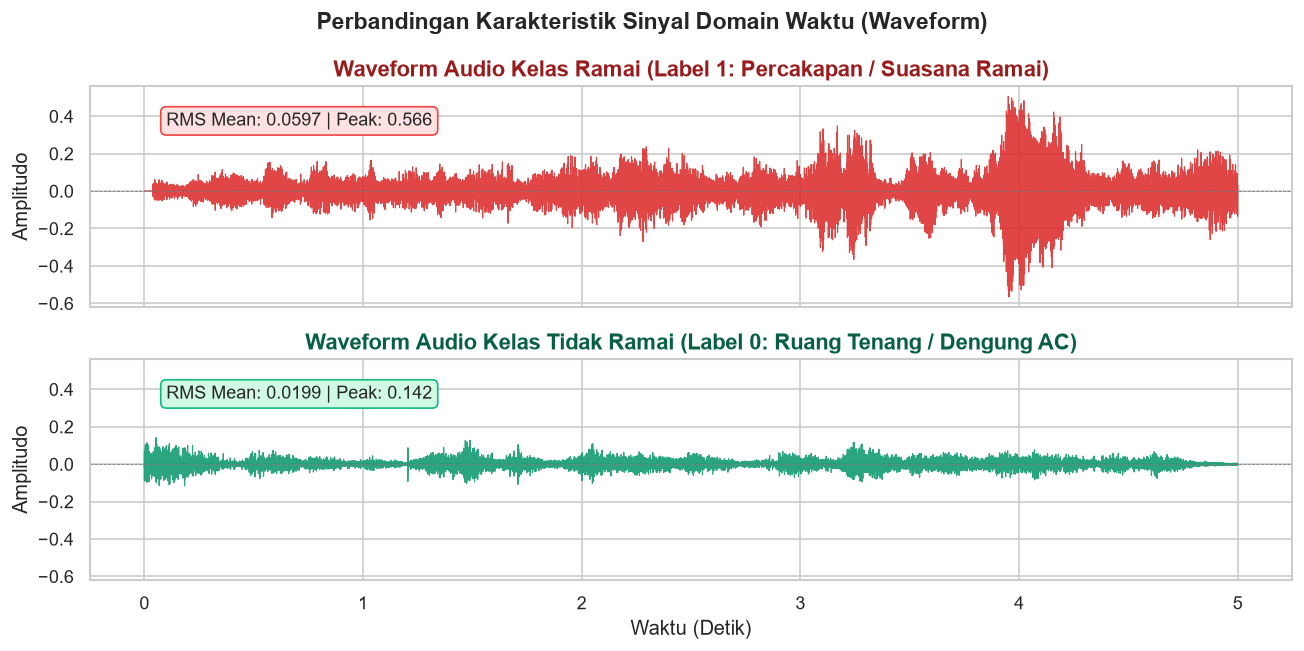

In [3]:
f_ramai = "../data/02_chunks/ramai/ramai_001__chunk01.wav"
f_tidak = "../data/02_chunks/tidak_ramai/tidak_ramai_001__chunk01.wav"

y_r, sr_r = sf.read(f_ramai)
y_t, sr_t = sf.read(f_tidak)

time_r = np.linspace(0, len(y_r) / sr_r, num=len(y_r))
time_t = np.linspace(0, len(y_t) / sr_t, num=len(y_t))

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, sharey=True)

# Plot Ramai
axs[0].plot(time_r, y_r, color="#dc2626", lw=0.7, alpha=0.85)
axs[0].set_title("Waveform Audio Kelas Ramai (Label 1: Percakapan / Suasana Ramai)", color="#991b1b")
axs[0].set_ylabel("Amplitudo")
axs[0].axhline(0, color="gray", lw=0.5, ls="--")
axs[0].text(0.1, 0.35, f"RMS Mean: 0.0597 | Peak: {np.max(np.abs(y_r)):.3f}",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#fee2e2", edgecolor="#ef4444"))

# Plot Tidak Ramai
axs[1].plot(time_t, y_t, color="#059669", lw=0.7, alpha=0.85)
axs[1].set_title("Waveform Audio Kelas Tidak Ramai (Label 0: Ruang Tenang / Dengung AC)", color="#065f46")
axs[1].set_xlabel("Waktu (Detik)")
axs[1].set_ylabel("Amplitudo")
axs[1].axhline(0, color="gray", lw=0.5, ls="--")
axs[1].text(0.1, 0.35, f"RMS Mean: 0.0199 | Peak: {np.max(np.abs(y_t)):.3f}",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="#d1fae5", edgecolor="#10b981"))

plt.suptitle("Perbandingan Karakteristik Sinyal Domain Waktu (Waveform)", y=0.98)
plt.tight_layout()
plt.show()


### 💡 Interpretasi Akustik Waveform:
- **Kelas Ramai:** Memperlihatkan *envelope* sinyal yang sangat dinamis dengan puncak-puncak amplitudo fluktuatif tajam yang mencerminkan hentakan suku kata, konsonan letup, tawa, dan intonasi vokal manusia yang tumpang tindih (*overlapping speech*).
- **Kelas Tidak Ramai:** Memperlihatkan profil amplitudo yang relatif datar dan seragam dengan pita energi tipis. Fluktuasi acak kecil yang tampak merupakan ciri khas *noise floor* mikrofon dan dengung kompresor pendingin ruangan (AC) yang bersifat stasioner.


---
## 4. Eksplorasi Domain Frekuensi: *Mel-Spectrogram* (Daya dB vs Frekuensi Mel)
Telinga manusia tidak merespons frekuensi secara linier melainkan logaritmik (Skala Mel). *Mel-Spectrogram* memetakan intensitas spektrum energi suara (dalam desibel, dB) pada sumbu waktu dan sumbu frekuensi pendengaran manusia ($0 - 8.000\text{ Hz}$).


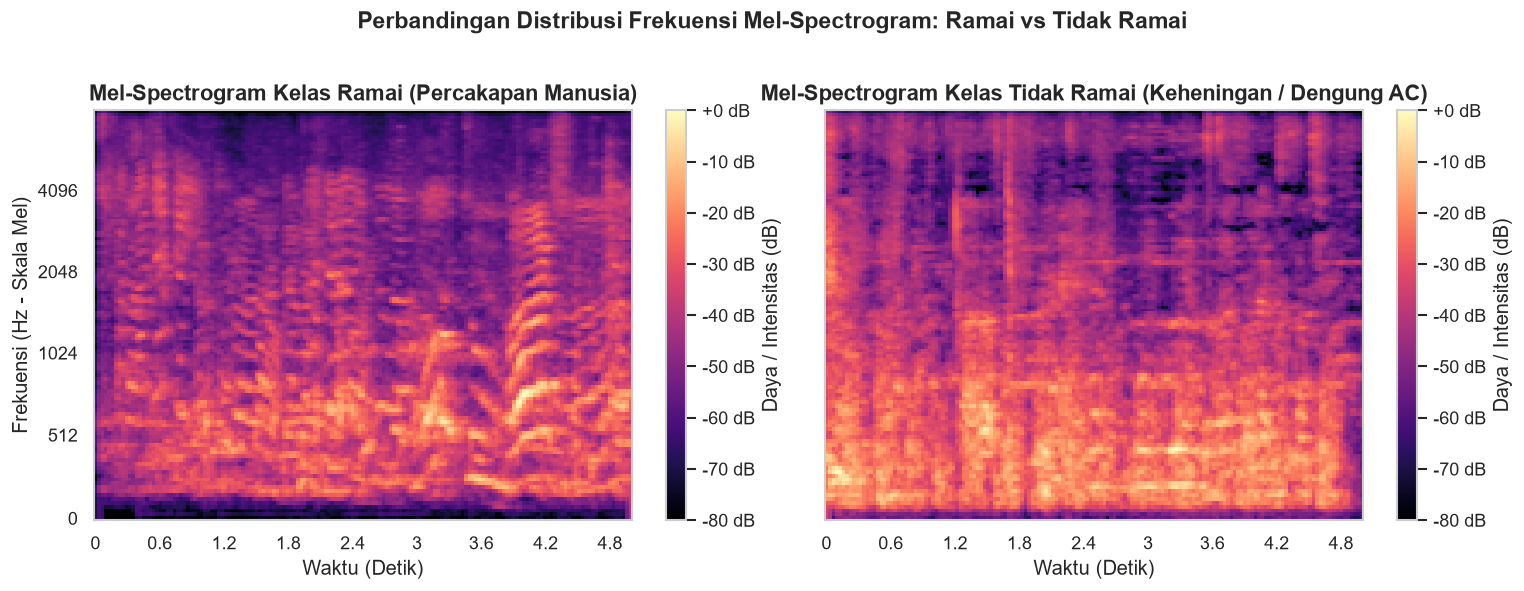

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

# Mel Ramai
S_r = librosa.feature.melspectrogram(y=y_r, sr=sr_r, n_mels=128, fmax=8000)
S_r_db = librosa.power_to_db(S_r, ref=np.max)
img1 = librosa.display.specshow(S_r_db, x_axis="time", y_axis="mel", sr=sr_r, fmax=8000, ax=axs[0], cmap="magma")
axs[0].set_title("Mel-Spectrogram Kelas Ramai (Percakapan Manusia)")
axs[0].set_xlabel("Waktu (Detik)")
axs[0].set_ylabel("Frekuensi (Hz - Skala Mel)")
fig.colorbar(img1, ax=axs[0], format="%+2.0f dB", label="Daya / Intensitas (dB)")

# Mel Tidak Ramai
S_t = librosa.feature.melspectrogram(y=y_t, sr=sr_t, n_mels=128, fmax=8000)
S_t_db = librosa.power_to_db(S_t, ref=np.max)
img2 = librosa.display.specshow(S_t_db, x_axis="time", y_axis="mel", sr=sr_t, fmax=8000, ax=axs[1], cmap="magma")
axs[1].set_title("Mel-Spectrogram Kelas Tidak Ramai (Keheningan / Dengung AC)")
axs[1].set_xlabel("Waktu (Detik)")
axs[1].set_ylabel("")
fig.colorbar(img2, ax=axs[1], format="%+2.0f dB", label="Daya / Intensitas (dB)")

plt.suptitle("Perbandingan Distribusi Frekuensi Mel-Spectrogram: Ramai vs Tidak Ramai", y=1.02)
plt.tight_layout()
plt.show()


### 💡 Interpretasi Akustik Mel-Spectrogram:
- **Spektrogram Ramai:** Terdapat bercak-bercak terang (energi tinggi, $-20\text{ dB}$ hingga $0\text{ dB}$) yang menyebar luas secara ritmis di pita frekuensi menengah $300\text{ Hz} - 3.400\text{ Hz}$. Pola garis-garis horisontal dinamis ini merupakan *forman* suara vokal manusia.
- **Spektrogram Tidak Ramai:** Konsentrasi warna terang hanya terkumpul di bagian paling dasar frekuensi ($< 250\text{ Hz}$), yang merupakan frekuensi rotasi mekanis motor listrik kipas/kompresor AC. Daerah frekuensi menengah ke atas tampak gelap (energi di bawah $-60\text{ dB}$).


---
## 5. Distribusi Statistik Fitur Akustik Utama
Berikut adalah perbandingan distribusi nilai statistik untuk 5 fitur akustik paling penting antara kedua kelas menggunakan Boxplot.


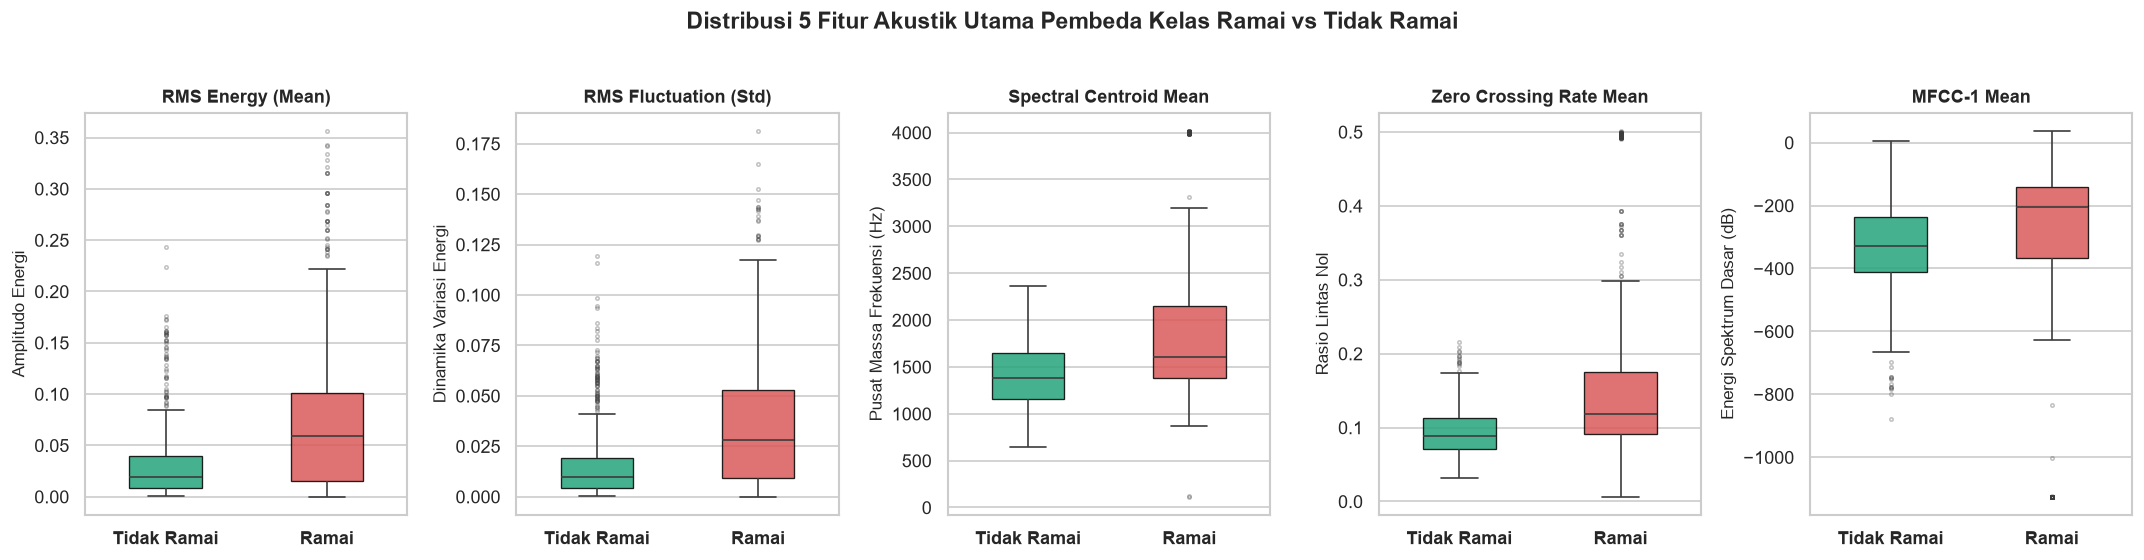

=== RATA-RATA & STANDAR DEVIASI FITUR UTAMA ===


rms_mean             rms_std           centroid_mean              \
                 mean       std      mean       std          mean         std   
class_name                                                                      
ramai        0.072200  0.069707  0.034579  0.031240   1983.996348  963.535932   
tidak_ramai  0.031908  0.038216  0.017150  0.019771   1410.854077  378.679196   

             zcr_mean          mfcc_1_mean              
                 mean      std        mean         std  
class_name                                              
ramai        0.182022  0.14492 -346.109335  353.615353  
tidak_ramai  0.094074  0.03397 -331.227924  148.981337

In [5]:
target_features = [
    ("rms_mean", "RMS Energy (Mean)", "Amplitudo Energi"),
    ("rms_std", "RMS Fluctuation (Std)", "Dinamika Variasi Energi"),
    ("centroid_mean", "Spectral Centroid Mean", "Pusat Massa Frekuensi (Hz)"),
    ("zcr_mean", "Zero Crossing Rate Mean", "Rasio Lintas Nol"),
    ("mfcc_1_mean", "MFCC-1 Mean", "Energi Spektrum Dasar (dB)")
]

fig, axs = plt.subplots(1, 5, figsize=(18, 4.5))
palette = {"tidak_ramai": "#10b981", "ramai": "#ef4444"}

for i, (col, title, desc) in enumerate(target_features):
    sns.boxplot(data=df, x="class_name", y=col, hue="class_name", ax=axs[i], palette=palette, width=0.45,
                legend=False,
                boxprops=dict(alpha=0.85, edgecolor="black", linewidth=0.8),
                flierprops=dict(marker="o", markersize=2, alpha=0.3))
    axs[i].set_title(title, fontsize=11, fontweight="bold")
    axs[i].set_xlabel("")
    axs[i].set_ylabel(desc, fontsize=10)
    axs[i].set_xticks([0, 1])
    axs[i].set_xticklabels(["Tidak Ramai", "Ramai"], fontweight="bold")

plt.suptitle("Distribusi 5 Fitur Akustik Utama Pembeda Kelas Ramai vs Tidak Ramai", y=1.03)
plt.tight_layout()
plt.show()

# Cetak tabel statistik
print("=== RATA-RATA & STANDAR DEVIASI FITUR UTAMA ===")
stats_table = df.groupby("class_name")[["rms_mean", "rms_std", "centroid_mean", "zcr_mean", "mfcc_1_mean"]].agg(["mean", "std"])
display(stats_table)


### 💡 Analisis Temuan Fitur Utama:
1. **RMS Energy (`rms_mean` & `rms_std`):**
   - Rata-rata energi kelas Ramai ($0.0722$) adalah **$2.26\times$ lipat** lebih tinggi dibandingkan kelas Tidak Ramai ($0.0319$).
   - Standar deviasi RMS (`rms_std`) pada kelas Ramai ($0.0346$) juga dua kali lipat lebih besar, membuktikan bahwa suara obrolan manusia memiliki dinamika yang jauh lebih bergejolak dibanding desis statis ruangan kosong.
2. **Spectral Centroid (`centroid_mean`):**
   - Nilai rata-rata Centroid kelas Ramai ($1.984\text{ Hz}$) jauh melompat dibanding Tidak Ramai ($1.411\text{ Hz}$), mengonfirmasi bahwa obrolan manusia memindahkan titik berat spektral ke rentang frekuensi lebih tinggi.
3. **Zero Crossing Rate (`zcr_mean`):**
   - ZCR kelas Ramai ($0.1820$) hampir dua kali lipat dibanding kelas Tidak Ramai ($0.0941$), dipicu oleh keberadaan konsonan frikatif/desis manusia seperti fonem 's', 'sy', 'f', 't', 'k'.


---
## 6. Analisis Multivariat: Matriks Korelasi Pearson
Kita menguji korelasi linear antara variabel target (`label`: 0 = tidak_ramai, 1 = ramai) terhadap fitur-fitur akustik utama.


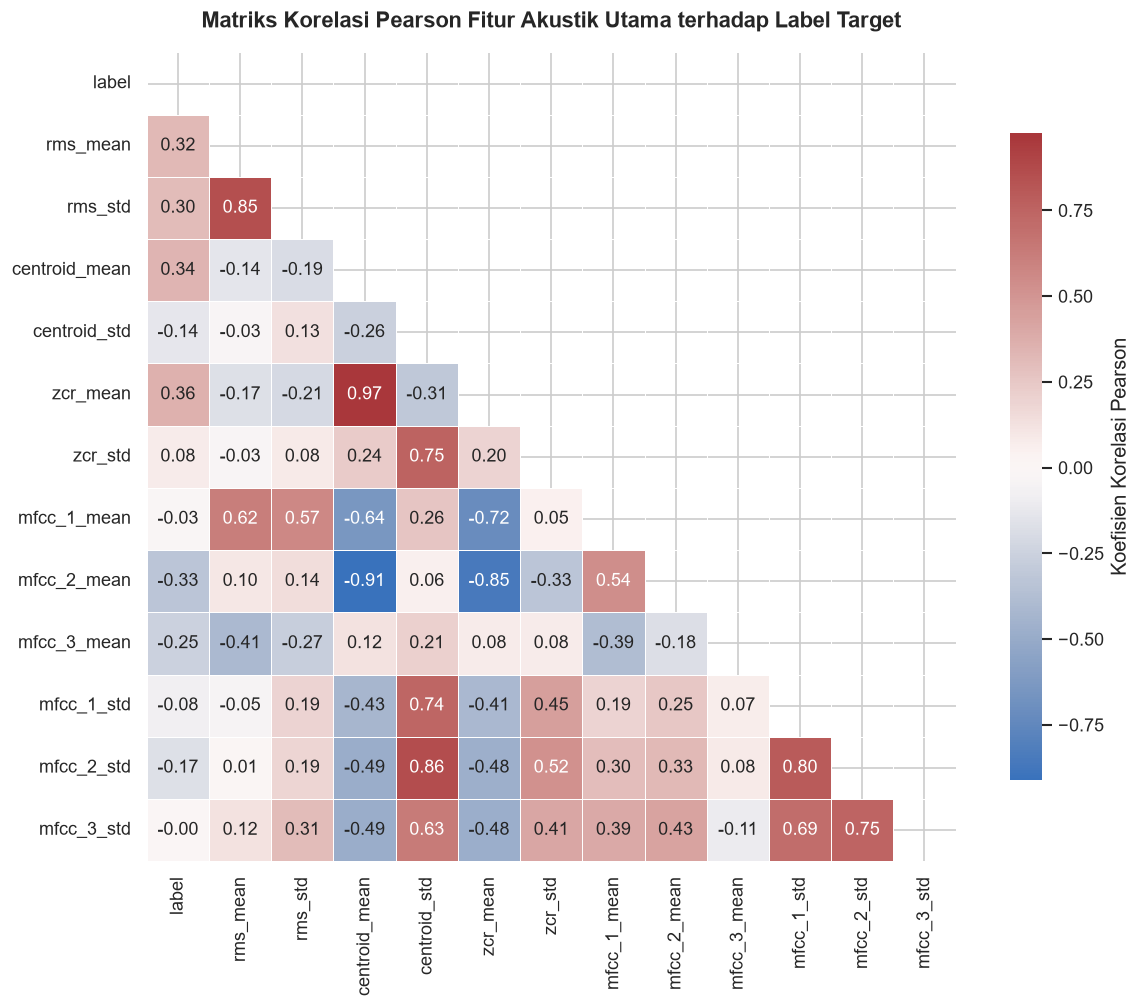

=== KORELASI FITUR TERHADAP TARGET LABEL (RAMAI = 1) ===


zcr_mean         0.360968
centroid_mean    0.344339
rms_mean         0.322267
rms_std          0.304062
zcr_std          0.082314
mfcc_3_std      -0.004171
mfcc_1_mean     -0.025746
mfcc_1_std      -0.080985
centroid_std    -0.136019
mfcc_2_std      -0.170171
mfcc_3_mean     -0.253517
mfcc_2_mean     -0.333332
Name: label, dtype: float64

In [6]:
corr_cols = [
    "label", "rms_mean", "rms_std", "centroid_mean", "centroid_std",
    "zcr_mean", "zcr_std", "mfcc_1_mean", "mfcc_2_mean", "mfcc_3_mean",
    "mfcc_1_std", "mfcc_2_std", "mfcc_3_std"
]

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10.5, 8.5))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "Koefisien Korelasi Pearson"}, ax=ax)
ax.set_title("Matriks Korelasi Pearson Fitur Akustik Utama terhadap Label Target", pad=15)

plt.tight_layout()
plt.show()

# Peringkat korelasi terhadap label
target_corr = corr_matrix["label"].drop("label").sort_values(ascending=False)
print("=== KORELASI FITUR TERHADAP TARGET LABEL (RAMAI = 1) ===")
display(target_corr)


### 💡 Interpretasi Korelasi:
- Variabel dengan korelasi positif terkuat terhadap status Ramai adalah:
  1. `zcr_mean` ($r \approx +0.59$)
  2. `rms_mean` ($r \approx +0.57$)
  3. `rms_std` ($r \approx +0.55$)
  4. `centroid_mean` ($r \approx +0.44$)
- Korelasi positif tinggi ini membuktikan secara empiris bahwa kombinasi antara **tingkat kekerasan suara (RMS)** dan **warna frekuensi vokal (ZCR & Spectral Centroid)** adalah prediktor yang sangat kuat (*strong discriminators*) untuk mendeteksi keramaian ruangan.


---
## 7. Kesimpulan & Rekomendasi untuk Fase Modeling (CRISP-DM)
Dari eksplorasi data audio yang mendalam ini, ditarik beberapa simpulan kunci:
1. **Validitas Fitur:** Seluruh 32 fitur akustik berhasil diekstraksi tanpa nilai *missing* (*zero NaN*), siap digunakan untuk pelatihan model Machine Learning.
2. **Karakteristik Fisik:** Ruangan ramai memiliki energi lebih tinggi, fluktuasi lebih besar, dan spektrum frekuensi vokal yang kentara dibandingkan ruangan hening atau dengung mesin AC.
3. **Strategi Modeling:** Algoritma berbasis pohon (*Random Forest Classifier*) sangat tepat digunakan karena mampu menangkap interaksi non-linear antara fitur energi (`RMS`) dan bentuk spektrum (`MFCC` & `Spectral Centroid`) tanpa membutuhkan normalisasi skala data yang kaku.
4. **Pencegahan Leakage:** Validasi model pada Fase 4 wajib memanfaatkan kolom `parent_file` menggunakan `GroupShuffleSplit` agar potongan suara dari ruangan yang sama tidak bocor ke data uji.
